# Amazon 2014: saved DUPGT training results



## 1. Load the completed run

This cell finds the project folder and reads three saved records: `config.json` holds the settings, `dataset_manifest.json` describes the data split, and `metrics.json` holds the final results. It also confirms that the run finished. No dataset scanning or model fitting happens here.

In [1]:
from pathlib import Path
import gc, json, sys
import numpy as np
import pandas as pd
import torch
from IPython.display import Image, display
ROOT=next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'src/dupgt_cdr').is_dir())
sys.path.insert(0,str(ROOT/'src'))
YEAR='2014'
RUN=ROOT/f'outputs/amazon{YEAR}/full_seed2020'
RUNS={YEAR:RUN}
CONFIG=json.loads((RUN/'config.json').read_text())
DATASET=json.loads((RUN/'dataset_manifest.json').read_text())
METRICS=json.loads((RUN/'metrics.json').read_text())
assert METRICS['status']=='completed'
print('Run:',RUN)
print('Device:',METRICS['environment']['device'],'| Seed:',METRICS['seed'])

Run: /Users/parjanyapandey/Programming/Masters/Data Mining/dupgt-cdr/outputs/amazon2014/full_seed2020
Device: cpu | Seed: 2020


## 2. Dataset and held-out users

A **shared user** has Book and Movie ratings in the raw data. We do a *target-user cold-start* test.

The cell below reads counts from the saved manifest, so it is quick even though the raw files are large.

In [2]:
m=DATASET
summary=pd.DataFrame([
 ['Book ratings read',m['raw']['source_ratings']],
 ['Movie ratings read',m['raw']['target_ratings']],
 ['Users in both domains',m['cohort']['shared_users']],
 ['Held-out Movie test users',m['splits']['test']['users']],
 ['Held-out Movie ratings',m['splits']['test']['ratings']],
],columns=['Quantity','Count'])
display(summary.style.format({'Count':'{:,.0f}'}))
splits=pd.DataFrame([[name.replace('_',' ').title(),v['users'],v['ratings']]
 for name,v in m['splits'].items()],columns=['Saved split','Users','Ratings'])
display(splits.style.format({'Users':'{:,.0f}','Ratings':'{:,.0f}'}))
print('Unseen Movie items excluded from test:',m['evaluation_filter']['test_cold_item_rows_excluded'])

,Quantity,Count
0,Book ratings read,"8,898,041"
1,Movie ratings read,"1,697,533"
2,Users in both domains,"37,388"
3,Held-out Movie test users,"7,478"
4,Held-out Movie ratings,"163,789"


,Saved split,Users,Ratings
0,Source Train,"603,668","8,898,041"
1,Target Train,"112,743","1,446,273"
2,Meta Train,"26,171","541,059"
3,Validation,"3,739","87,463"
4,Test,"7,478","163,789"


Unseen Movie items excluded from test: 6


## 3. Training stages and settings

First the code learns Book and Movie factors from ratings. 
Then a **linear mapping** learns a simple Book-to-Movie bridge. 
Finally, **DUPGT** builds separate paths for high Book ratings (4–5) and low ratings (1–3) and learns how to mix them for a candidate Movie.

This cell *displays* the settings that were used. The training loops are in [`train.py`](../src/dupgt_cdr/train.py), and the DUPGT network is in [`upstream.py`](../src/dupgt_cdr/upstream.py) and [`model.py`](../src/dupgt_cdr/model.py).

In [3]:
settings=pd.DataFrame([
 ['Book factors',CONFIG['pretrain_epochs'],CONFIG['pretrain_learning_rate'],'Book-side vectors'],
 ['Movie factors',CONFIG['pretrain_epochs'],CONFIG['pretrain_learning_rate'],'Movie-side vectors'],
 ['Linear mapping',CONFIG['mapping_epochs'],CONFIG['mapping_learning_rate'],'Simple Book-to-Movie transfer'],
 ['DUPGT',CONFIG['meta_epochs'],CONFIG['meta_learning_rate'],'High/low history with a learned gate'],
],columns=['Stage','Epochs','Learning rate','What is learned'])
display(settings)
print('Embedding dimension:',CONFIG['embedding_dim'])
print('Factor batch size:',CONFIG['batch_size'],'| DUPGT batch size:',CONFIG['meta_batch_size'])

,Stage,Epochs,Learning rate,What is learned
0,Book factors,15,0.02,Book-side vectors
1,Movie factors,15,0.02,Movie-side vectors
2,Linear mapping,30,0.01,Simple Book-to-Movie transfer
3,DUPGT,15,0.02,High/low history with a learned gate


Embedding dimension: 10
Factor batch size: 1024 | DUPGT batch size: 256


## 4. Training curves saved by the run

**Training MSE** is average squared error while fitting ratings. **Validation RMSE** is error on a separate group used to select transfer weights.

,stage,epoch,train_mse,validation_rmse
14,source_pretrain,15,0.2576,—
29,target_pretrain,15,0.2067,—
59,linear_mapping,30,0.3393,1.0957
74,dupgt,15,0.9804,1.0250


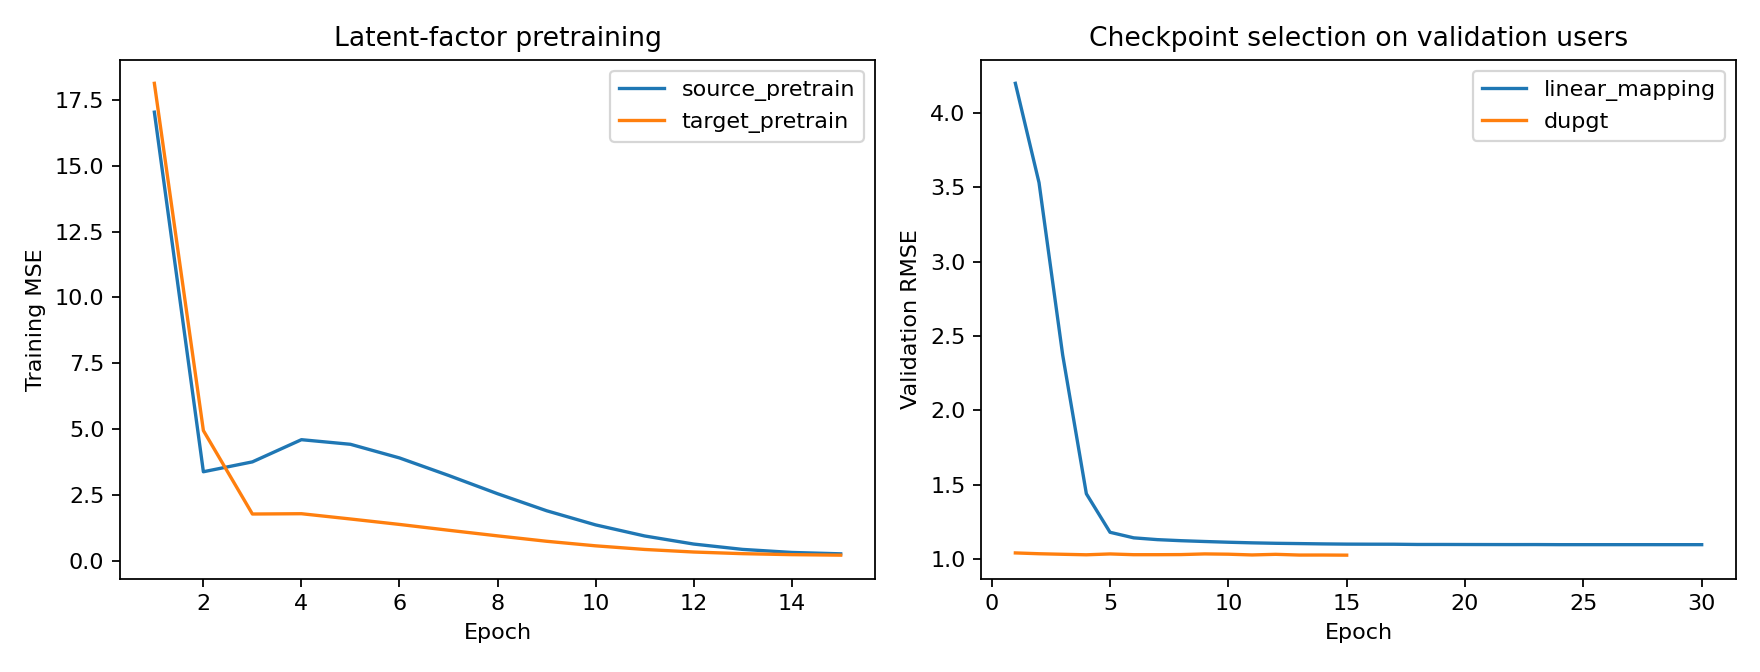

In [4]:
history=pd.read_csv(RUN/'training_history.csv')
last=history.groupby('stage',sort=False).tail(1)[['stage','epoch','train_mse','validation_rmse']]
display(last.style.format({'train_mse':'{:.4f}','validation_rmse':'{:.4f}'},na_rep='—'))
display(Image(filename=str(RUN/'training_curves.png')))

## 5. Saved checkpoints

A **checkpoint** is a file of learned weights. Factor weights were saved after pretraining. The linear-mapping and DUPGT checkpoints were selected using the lowest *validation* RMSE, before checking the test scores. This cell shows the selected epochs; it does not choose new weights.

In [14]:
chosen=METRICS['selected_checkpoints']
checkpoints=pd.DataFrame([
 ['Linear mapping','linear_mapping_best.pt',chosen['linear_mapping']['epoch'],chosen['linear_mapping']['validation']['rmse']],
 ['DUPGT','dupgt_best.pt',chosen['dupgt']['epoch'],chosen['dupgt']['validation']['rmse']],
],columns=['Model','Weight file','Selected epoch','Validation RMSE'])
display(checkpoints.style.format({'Validation RMSE':'{:.4f}'}))
print('Factor weights: pretrained_factors.pt')

,Model,Weight file,Selected epoch,Validation RMSE
0,Linear mapping,linear_mapping_best.pt,28,1.0957
1,DUPGT,dupgt_best.pt,15,1.0250


Factor weights: pretrained_factors.pt


## 6. Held-out test scores

**MAE** is average absolute error in stars. **RMSE** penalizes large errors more. Both should be lower. Global mean predicts one training average; Movie mean predicts each Movie's training average; linear mapping transfers a Book-user vector; DUPGT uses the high/low Book paths. The code reads the *raw* test metrics saved for the whole test set and displays the original `test_metrics.png` from the PDF.

,Model,Test MAE,Test RMSE
0,Global mean,0.9342,1.1813
1,Movie mean,0.8268,1.0757
2,Linear mapping,0.8630,1.1037
3,DUPGT,0.7879,1.0420


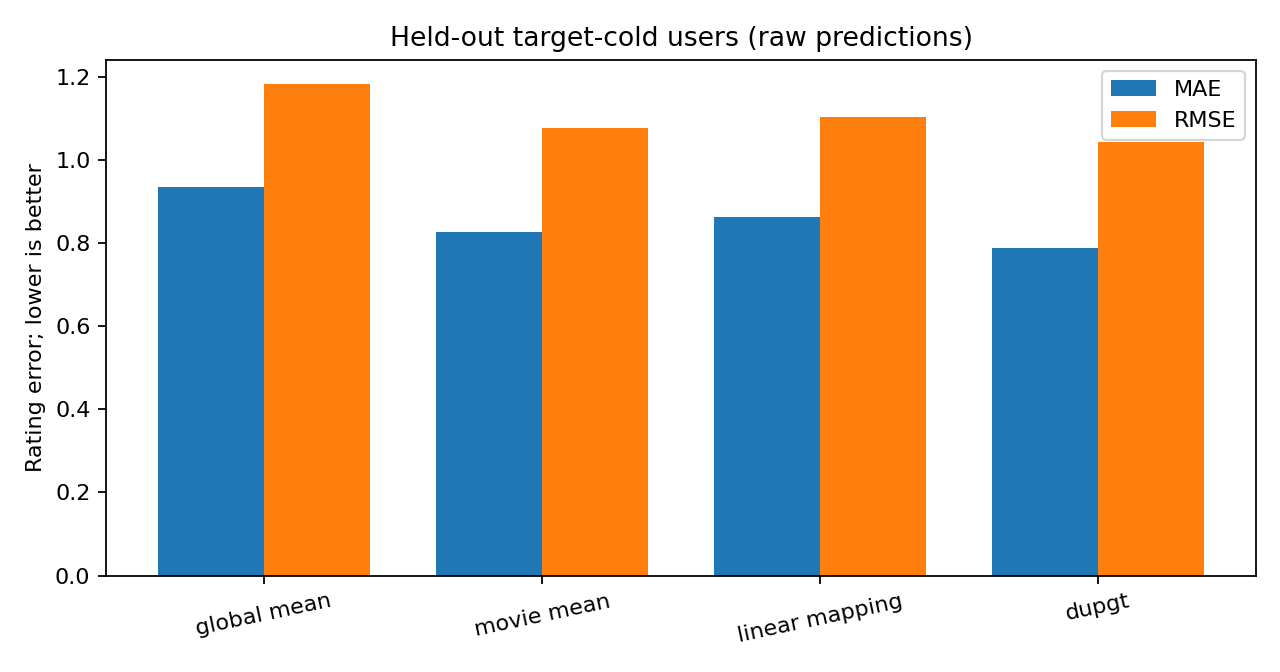

In [6]:
labels=[('global_mean','Global mean'),('movie_mean','Movie mean'),
        ('linear_mapping','Linear mapping'),('dupgt','DUPGT')]
results=pd.DataFrame([[name,METRICS['results'][key]['raw']['mae'],METRICS['results'][key]['raw']['rmse']]
 for key,name in labels],columns=['Model','Test MAE','Test RMSE'])
display(results.style.format({'Test MAE':'{:.4f}','Test RMSE':'{:.4f}'}))
display(Image(filename=str(RUN/'test_metrics.png')))

The next calculation compares DUPGT with **Movie mean on the same test rows**. Positive reductions mean DUPGT made smaller errors. This comparison is stronger evidence of useful Book-to-Movie transfer than comparing 2014 directly with 2023, because the releases contain different users and items.

In [7]:
base=METRICS['results']['movie_mean']['raw']
dupgt=METRICS['results']['dupgt']['raw']
print(f"MAE reduction: {base['mae']-dupgt['mae']:.4f} stars ({100*(base['mae']-dupgt['mae'])/base['mae']:.2f}%)")
print(f"RMSE reduction: {base['rmse']-dupgt['rmse']:.4f} stars ({100*(base['rmse']-dupgt['rmse'])/base['rmse']:.2f}%)")
print(f"Held-out Movie ratings evaluated: {dupgt['n_ratings']:,}")

MAE reduction: 0.0388 stars (4.70%)
RMSE reduction: 0.0337 stars (3.14%)
Held-out Movie ratings evaluated: 163,789


## 7. Gate and individual-user results

DUPGT combines a high-rated Book path and a low-rated Book path for each Movie. The **high gate** is its mixing weight, *not* a confidence probability. A lower overall error also does not mean every person benefited. This cell reads the saved user-level CSV and counts who had lower or higher MAE than Movie mean.

In [8]:
gate=METRICS['gate_summary']
print(f"Mean high-Book gate weight: {gate['mean_high_weight']:.3f}")
users=pd.read_csv(RUN/'user_metrics.csv')
diff=users['dupgt_minus_movie_mean_mae']
user_table=pd.DataFrame([
 ['DUPGT better',int((diff<0).sum()),100*(diff<0).mean()],
 ['Equal',int((diff==0).sum()),100*(diff==0).mean()],
 ['Movie mean better',int((diff>0).sum()),100*(diff>0).mean()],
],columns=['Per-user MAE comparison','Users','Share'])
display(user_table.style.format({'Users':'{:,.0f}','Share':'{:.1f}%'}))

Mean high-Book gate weight: 0.366


,Per-user MAE comparison,Users,Share
0,DUPGT better,"4,045",54.1%
1,Equal,0,0.0%
2,Movie mean better,"3,433",45.9%


## 8. A few saved prediction rows

This reads `example_predictions.csv`, a small excerpt of the complete test export. `actual_rating` is the withheld answer. `dupgt` is the raw model prediction, which can fall outside 1–5 before display clipping. The two gate weights add to one; the Book counts show how many high and low ratings the user had. The rating datasets contain product IDs, not Movie titles.

In [9]:
sample=pd.read_csv(RUN/'example_predictions.csv',nrows=8,dtype={'user_id':str,'movie_asin':str})
columns=['user_id','movie_asin','actual_rating','movie_mean','dupgt','alpha_high','alpha_low','source_high_count','source_low_count']
display(sample[columns].style.format({'movie_mean':'{:.3f}','dupgt':'{:.3f}',
                                      'alpha_high':'{:.3f}','alpha_low':'{:.3f}'}))

,user_id,movie_asin,actual_rating,movie_mean,dupgt,alpha_high,alpha_low,source_high_count,source_low_count
0,A3NM0RAYSL6PA8,B001ER4CSO,2,4.233,3.633,0.457,0.543,7,10
1,A3S6Z7A6SHC6KR,B0001CNRNO,5,4.027,3.554,0.503,0.497,3,4
2,A3UW0D8M5P642L,B00020DBHC,3,4.250,4.006,0.573,0.427,8,3
3,A22CC9ZGXEXB1V,B009AMAJBO,3,3.843,2.803,0.309,0.691,12,1
4,A29WXAG813FS7A,B0010YSDA4,5,3.903,4.495,0.314,0.686,8,0
5,A2BWZGD7S0JZQJ,B0010AN7MM,2,2.148,2.736,0.508,0.492,60,12
6,A32YQ3UU6IIE0A,6301996135,5,4.806,4.719,0.400,0.600,10,1
7,A1OOHB5H6DM6Y0,B001SGEUYW,1,2.674,1.785,0.397,0.603,3,3


## 9. Run the saved DUPGT weights once

This final demonstration reloads `dupgt_best.pt` and makes eight fresh predictions using real held-out user–Movie pairs and their Book histories. It checks that these match the original exported values. Loading the large arrays and checkpoint takes longer than the tables, but it **does not retrain**.

In [11]:
from dupgt_cdr.data import get_benchmark
from dupgt_cdr.model import DUPGTModel
from dupgt_cdr.settings import get_config

def run_saved_dupgt(year, n=8):
    config = get_config(year, "full")
    data, manifest = get_benchmark(config)
    run = RUNS[year]
    checkpoint = torch.load(run / "checkpoints/dupgt_best.pt", map_location="cpu", weights_only=True)
    assert checkpoint["dataset_sha256"] == manifest["benchmark_sha256"], "Checkpoint/data mismatch"
    torch.set_num_threads(4)
    model = DUPGTModel(**checkpoint["model_spec"])
    model.load_state_dict(checkpoint["model_state"])
    model.eval()

    rows = data["test"][:n]
    features = np.concatenate((rows[:, :2], data["histories"][rows[:, 0]]), axis=1)
    with torch.inference_mode():
        predicted, high_gate = model.forward_with_gate(torch.as_tensor(features, dtype=torch.long))
    predicted = predicted.numpy().reshape(-1)
    high_gate = high_gate.numpy().reshape(-1)
    exported = pd.read_csv(run / "test_predictions.csv.gz", nrows=n,
                           dtype={"user_id": str, "movie_asin": str})
    max_difference = float(np.max(np.abs(predicted - exported["dupgt"].to_numpy())))
    assert np.allclose(predicted, exported["dupgt"], atol=1e-5, rtol=1e-5)

    counts = data["polarity_counts"][rows[:, 0]]
    example = pd.DataFrame({"User ID": exported["user_id"], "Movie ID": exported["movie_asin"],
                            "Actual stars": rows[:, 2], "DUPGT prediction": predicted,
                            "Movie mean": exported["movie_mean"], "High gate": high_gate,
                            "High Books": counts[:, 0], "Low Books": counts[:, 1]})
    display(example.style.format({"DUPGT prediction": "{:.3f}", "Movie mean": "{:.3f}",
                                  "High gate": "{:.3f}"}))
    print(f"Amazon {year}: {n} live predictions match the saved export; maximum difference = {max_difference:.2g}")
    del data, checkpoint, model
    gc.collect()
    return example

In [12]:
live_example=run_saved_dupgt(YEAR, n=8)

,User ID,Movie ID,Actual stars,DUPGT prediction,Movie mean,High gate,High Books,Low Books
0,A3VT62AP8KEK3V,0005019281,4,4.380,4.500,0.373,17,3
1,A38JFF6SGZEO37,0005019281,5,4.660,4.500,0.254,14,1
2,A2PSMIRDHYYONP,0005019281,5,4.537,4.500,0.238,7,0
3,A2ZPPV9EVM45UH,0005019281,3,4.662,4.500,0.265,14,0
4,A1UQEOKS2MQOAS,0005019281,4,4.636,4.500,0.329,11,2
5,AIMVNK843DDSK,0005019281,4,4.500,4.500,0.377,7,3
6,A2JP0URFHXP6DO,0005019281,3,4.656,4.500,0.349,573,37
7,ADES8B01WRPI3,0005119367,5,4.897,4.810,0.332,50,4


Amazon 2014: 8 live predictions match the saved export; maximum difference = 0
